<a href="https://colab.research.google.com/github/Lorenzo-v8/Top_10_criptomonedas_DataAnalisis/blob/main/top10_criptomonedas_market_cap.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Top 10 Criptomonedas por Market Cap
**Análisis exploratorio de datos sobre tamaño, liquidez y estructura del mercado cripto**


Este notebook analiza una foto actual de las 10 criptomonedas más grandes por capitalización de mercado, con el objetivo de entender cómo se distribuye el tamaño del mercado, qué monedas concentran mayor actividad de trading en relación a su tamaño, y qué rol cumplen las stablecoins.

Fuente de datos: [CoinGecko API](https://www.coingecko.com/en/api) (gratuita, sin API key).

In [10]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROJO, GRIS = "#e30613", "#4a4a4a"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def es(x, d=1):
    """Formato numérico español: 1.234,5"""
    return f"{x:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".")

## 0. Carga de datos

In [11]:
URL = "https://api.coingecko.com/api/v3/coins/markets"
params = dict(vs_currency="usd", order="market_cap_desc", per_page=10, page=1)

try:
    r = requests.get(URL, params=params, timeout=30)
    r.raise_for_status()
    df = pd.DataFrame(r.json())[["name", "symbol", "current_price", "market_cap", "total_volume"]]
    df.to_csv("top10_cripto.csv", index=False)
    print("Datos descargados de CoinGecko y guardados en top10_cripto.csv")
except Exception as e:
    print("No se pudo usar la API:", e)
    print("Cargando copia local top10_cripto.csv")
    df = pd.read_csv("top10_cripto.csv")

df = df.rename(columns={"total_volume": "volumen_24h"})
df

Datos descargados de CoinGecko y guardados en top10_cripto.csv


,name,symbol,current_price,market_cap,volumen_24h
0,Bitcoin,btc,60275.000000,1212686271876,40306908913
1,Ethereum,eth,1698.730000,207663710014,15395580008
2,Tether,usdt,0.999042,174671014134,61768312578
3,BNB,bnb,550.140000,72353903414,748720151
4,USDC,usdc,0.999562,69022249992,16915538988
5,XRP,xrp,0.932121,59205755042,2487461466
6,Solana,sol,70.740000,41887880420,3757891414
7,TRON,trx,0.307531,29232410980,395927263
8,Figure Heloc,figr_heloc,1.042000,28284185750,14025861
9,Hyperliquid,hype,62.960000,14962585027,1214915035


## 1. Métricas derivadas

In [12]:
STABLECOINS = ["usdt", "usdc"]

df["tipo"] = np.where(df["symbol"].str.lower().isin(STABLECOINS), "Stablecoin", "Criptomoneda")
df["participacion"] = df["market_cap"] / df["market_cap"].sum() * 100
df["liquidez"] = df["volumen_24h"] / df["market_cap"]          # volumen / market cap

total_mc = df["market_cap"].sum()
btc_share = df.loc[df["symbol"] == "btc", "participacion"].iloc[0]
top_liq = df.loc[df["liquidez"].idxmax(), "name"]
stable_vol_share = df.loc[df["tipo"] == "Stablecoin", "volumen_24h"].sum() / df["volumen_24h"].sum() * 100

print(f"{es(btc_share)}%  del market cap del top 10 es de Bitcoin")
print(f"{top_liq}  moneda más líquida en relación a su tamaño")
print(f"{es(stable_vol_share)}%  del volumen total lo mueven las stablecoins")
print(f"US$ {es(total_mc / 1e12, 2)} B  market cap total del top 10")

63,5%  del market cap del top 10 es de Bitcoin
Tether  moneda más líquida en relación a su tamaño
55,0%  del volumen total lo mueven las stablecoins
US$ 1,91 B  market cap total del top 10


## 2. Un mercado dominado por Bitcoin
La concentración es tan fuerte que graficar el market cap en escala lineal deja al resto casi invisible frente a Bitcoin, por eso se usa **escala logarítmica**.

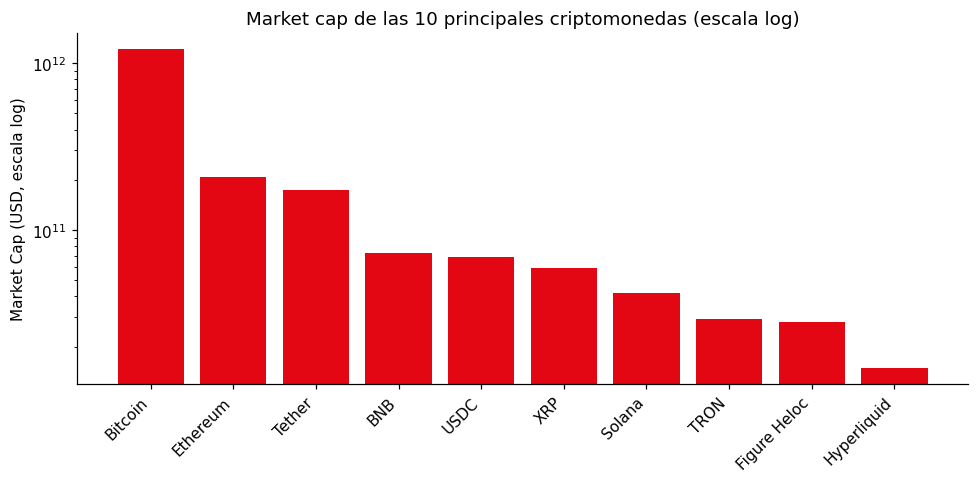

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(df["name"], df["market_cap"], color=ROJO)
ax.set_yscale("log")
ax.set_ylabel("Market Cap (USD, escala log)")
ax.set_title("Market cap de las 10 principales criptomonedas (escala log)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 3. Tamaño no es lo mismo que actividad de trading
Se compara market cap contra volumen operado en 24h (ambos ejes en escala log).

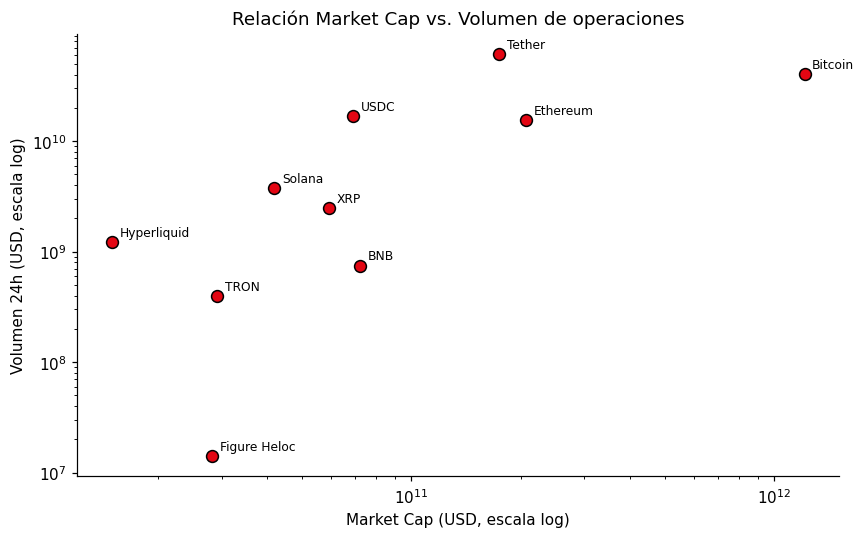

In [14]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df["market_cap"], df["volumen_24h"], color=ROJO, edgecolor="black", s=60, zorder=3)
for _, row in df.iterrows():
    ax.annotate(row["name"], (row["market_cap"], row["volumen_24h"]),
                textcoords="offset points", xytext=(5, 4), fontsize=8)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Market Cap (USD, escala log)")
ax.set_ylabel("Volumen 24h (USD, escala log)")
ax.set_title("Relación Market Cap vs. Volumen de operaciones")
plt.tight_layout()
plt.show()

## 4. Participación en el mercado
Se agrupan las 5 monedas más chicas del top 10 en la categoría "Otros" para simplificar la lectura.

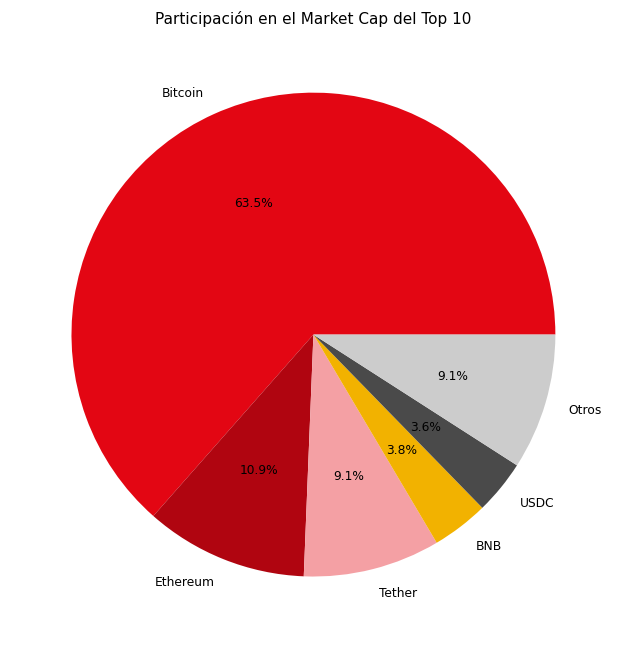

Las 2 monedas más grandes concentran el 74,4% del market cap analizado.


In [15]:
top5 = df.nlargest(5, "market_cap")
otros = pd.Series({"name": "Otros", "market_cap": df["market_cap"].sum() - top5["market_cap"].sum()})
pie = pd.concat([top5[["name", "market_cap"]], otros.to_frame().T], ignore_index=True)
pie["market_cap"] = pie["market_cap"].astype(float)

colores = [ROJO, "#b00510", "#f4a0a4", "#f2b200", GRIS, "#cccccc"]
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(pie["market_cap"], labels=pie["name"], colors=colores,
       autopct="%1.1f%%", textprops={"fontsize": 8})
ax.set_title("Participación en el Market Cap del Top 10", fontsize=10)
plt.tight_layout()
plt.show()

btc_eth = df.nlargest(2, "market_cap")["participacion"].sum()
print(f"Las 2 monedas más grandes concentran el {es(btc_eth)}% del market cap analizado.")

## 5. ¿Qué moneda se negocia más en relación a su tamaño?
Ratio **volumen / market cap**: valores altos indican que la moneda se opera con mucha frecuencia respecto a su tamaño.

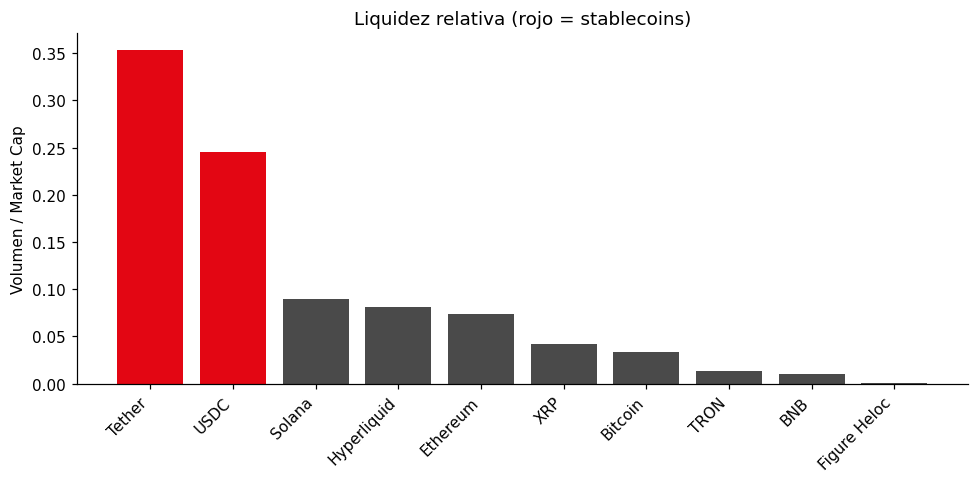

  name  liquidez
Tether      0.35
  USDC      0.25
Solana      0.09

Ratios más bajos:
        name  liquidez
        TRON      0.01
         BNB      0.01
Figure Heloc      0.00


In [16]:
liq = df.sort_values("liquidez", ascending=False)
colores = [ROJO if t == "Stablecoin" else GRIS for t in liq["tipo"]]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(liq["name"], liq["liquidez"], color=colores)
ax.set_ylabel("Volumen / Market Cap")
ax.set_title("Liquidez relativa (rojo = stablecoins)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print(liq[["name", "liquidez"]].head(3).round(2).to_string(index=False))
print("\nRatios más bajos:")
print(liq[["name", "liquidez"]].tail(3).round(2).to_string(index=False))

## 6. El rol distinto de las stablecoins
Las stablecoins representan una porción menor del market cap total, pero concentran una gran parte del volumen operado. No buscan revalorizarse: sirven como puente estable para mover valor entre otros activos.

,market_cap,volumen_24h,% market cap,% volumen
tipo,,,,
Criptomoneda,1666276702523,64321430111,87.2,45.0
Stablecoin,243693264126,78683851566,12.8,55.0


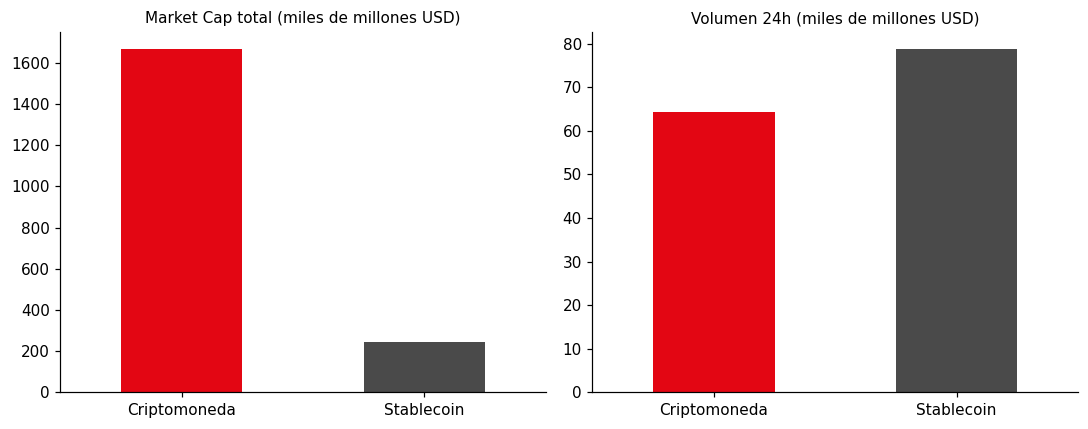

In [17]:
res = df.groupby("tipo")[["market_cap", "volumen_24h"]].sum()
res["% market cap"] = res["market_cap"] / res["market_cap"].sum() * 100
res["% volumen"] = res["volumen_24h"] / res["volumen_24h"].sum() * 100
display(res.round(1))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col, titulo in zip(axes, ["market_cap", "volumen_24h"],
                           ["Market Cap total (miles de millones USD)", "Volumen 24h (miles de millones USD)"]):
    (res[col] / 1e9).plot.bar(ax=ax, color=[ROJO, GRIS], rot=0)
    ax.set_title(titulo, fontsize=10)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

## Conclusiones

In [19]:
from IPython.display import Markdown

btc_vol = df.loc[df["symbol"] == "btc", "volumen_24h"].iloc[0]
usdt_vol = df.loc[df["symbol"] == "usdt", "volumen_24h"].iloc[0]
stable_mc_share = res.loc["Stablecoin", "% market cap"]

Markdown(f"""
- El mercado cripto top 10 está fuertemente concentrado: las dos monedas más grandes explican el **{es(btc_eth, 0)}%** del market cap total analizado.
- Tamaño de mercado y volumen de trading no son lo mismo: Tether mueve **US$ {es(usdt_vol/1e6, 0)} M** diarios frente a **US$ {es(btc_vol/1e6, 0)} M** de Bitcoin.
- Bitcoin tiene un ratio de liquidez relativa de **{es(df.loc[df['symbol']=='btc','liquidez'].iloc[0], 2)}**, bajo frente a otras monedas: se comporta más como reserva de valor que como activo de trading frecuente.
- Las stablecoins representan el **{es(stable_mc_share)}%** del market cap pero concentran el **{es(stable_vol_share)}%** del volumen: confirman su rol como "puente" del ecosistema cripto.

*Análisis realizado en Python (pandas + matplotlib) como proyecto de portfolio de ciencia de datos.*
""")


- El mercado cripto top 10 está fuertemente concentrado: las dos monedas más grandes explican el **74%** del market cap total analizado.
- Tamaño de mercado y volumen de trading no son lo mismo: Tether mueve **US$ 61.768 M** diarios frente a **US$ 40.307 M** de Bitcoin.
- Bitcoin tiene un ratio de liquidez relativa de **0,03**, bajo frente a otras monedas: se comporta más como reserva de valor que como activo de trading frecuente.
- Las stablecoins representan el **12,8%** del market cap pero concentran el **55,0%** del volumen: confirman su rol como "puente" del ecosistema cripto.

*Análisis realizado en Python (pandas + matplotlib) como proyecto de portfolio de ciencia de datos.*
